In [1]:
!pip install -q tensorflow pandas matplotlib

In [2]:
import os, random, time
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

SEED = 42
def set_seed(s=SEED):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    tf.keras.utils.set_random_seed(s)
set_seed()

WINDOW, HORIZON, EPOCHS, BATCH = 45, 7, 60, 64

2921 kun: 2009-01-01 -> 2017-01-01


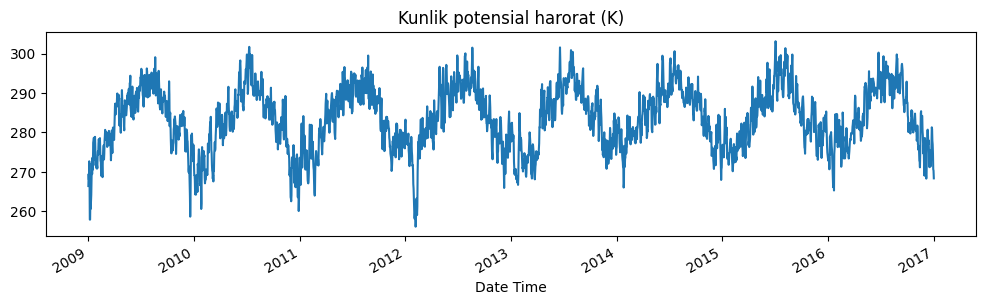

In [5]:
zip_path = tf.keras.utils.get_file(
    fname='jena_climate_2009_2016.csv.zip',
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip')

df = pd.read_csv(zip_path, compression='zip')
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
daily = df.set_index('Date Time')['Tpot (K)'].resample('D').mean().dropna()
print(len(daily), 'kun:', daily.index.min().date(), '->', daily.index.max().date())
daily.plot(figsize=(12, 3), title='Kunlik potensial harorat (K)'); plt.show()

In [6]:
values = daily.values.astype('float32')
n = len(values)
i_tr, i_va = int(n*0.70), int(n*0.85)          # 70% / 15% / 15% (vaqt tartibida)

mean, std = values[:i_tr].mean(), values[:i_tr].std()   # faqat train bo'yicha
scaled = (values - mean) / std

def make_windows(arr, start, end):
    # [start, end) dagi nishonlar uchun oldingi WINDOW kun kontekst sifatida olinadi
    X, y = [], []
    for t in range(max(start, WINDOW), end - HORIZON + 1):
        X.append(arr[t-WINDOW:t]); y.append(arr[t:t+HORIZON])
    return np.array(X)[..., None], np.array(y)

Xtr, ytr = make_windows(scaled, 0, i_tr)
Xva, yva = make_windows(scaled, i_tr, i_va)
Xte, yte = make_windows(scaled, i_va, n)
y_te_true = yte * std + mean                      # haqiqiy shkaladagi test nishonlari
print(Xtr.shape, Xva.shape, Xte.shape)

(1993, 45, 1) (432, 45, 1) (433, 45, 1)


In [12]:
def metrics(y, p):
    return dict(MAE=np.mean(np.abs(y-p)),
                RMSE=np.sqrt(np.mean((y-p)**2)),
                MAPE=np.mean(np.abs((y-p)/y))*100,
                MAE_day1=np.mean(np.abs(y[:,0]-p[:,0])),
                MAE_day7=np.mean(np.abs(y[:,-1]-p[:,-1])))

preds, rows, hists = {}, [], {}

# 1) Baseline: oxirgi qiymatni 7 kun takrorlash
base_pred = np.repeat((Xte[:, -1, 0] * std + mean)[:, None], HORIZON, axis=1)
preds['Baseline'] = base_pred
rows.append(dict(model='Baseline (oxirgi qiymat)', params=0, train_s=0, **metrics(y_te_true, base_pred)))

In [8]:
def build_lstm():
    set_seed()
    return models.Sequential([
        layers.Input((WINDOW, 1)),
        layers.LSTM(64, return_sequences=True, dropout=0.2),
        layers.LSTM(32, dropout=0.2),
        layers.Dense(HORIZON)], name='stacked_lstm')

def build_cnn():
    set_seed()
    return models.Sequential([
        layers.Input((WINDOW, 1)),
        layers.Conv1D(32, 5, padding='same', activation='relu'),
        layers.Conv1D(64, 5, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation='relu'),
        layers.Dense(HORIZON)], name='cnn1d_gap')

def train_eval(model, key, label):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    es = tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS,
                  batch_size=BATCH, callbacks=[es], verbose=2)
    dur = time.time() - t0
    p = model.predict(Xte, verbose=0) * std + mean
    preds[key] = p; hists[key] = h.history
    rows.append(dict(model=label, params=model.count_params(), train_s=round(dur),
                     **metrics(y_te_true, p)))

train_eval(build_lstm(), 'LSTM', 'Stacked LSTM (2 qatlam, dropout)')
train_eval(build_cnn(),  'CNN',  '1D-CNN + GAP')

res = pd.DataFrame(rows).set_index('model')
display(res.round(4)); res.to_csv('task7_results.csv')

Epoch 1/60
32/32 - 5s - 161ms/step - loss: 0.6204 - val_loss: 0.2608
Epoch 2/60
32/32 - 2s - 64ms/step - loss: 0.4460 - val_loss: 0.2586
Epoch 3/60
32/32 - 2s - 51ms/step - loss: 0.4567 - val_loss: 0.2561
Epoch 4/60
32/32 - 2s - 67ms/step - loss: 0.4448 - val_loss: 0.2568
Epoch 5/60
32/32 - 3s - 78ms/step - loss: 0.4409 - val_loss: 0.2505
Epoch 6/60
32/32 - 2s - 50ms/step - loss: 0.4297 - val_loss: 0.2487
Epoch 7/60
32/32 - 2s - 48ms/step - loss: 0.4330 - val_loss: 0.2464
Epoch 8/60
32/32 - 3s - 81ms/step - loss: 0.4007 - val_loss: 0.2457
Epoch 9/60
32/32 - 2s - 49ms/step - loss: 0.4142 - val_loss: 0.2547
Epoch 10/60
32/32 - 2s - 49ms/step - loss: 0.4309 - val_loss: 0.2448
Epoch 11/60
32/32 - 4s - 110ms/step - loss: 0.3922 - val_loss: 0.2457
Epoch 12/60
32/32 - 2s - 62ms/step - loss: 0.3996 - val_loss: 0.2421
Epoch 13/60
32/32 - 3s - 89ms/step - loss: 0.4359 - val_loss: 0.2411
Epoch 14/60
32/32 - 2s - 56ms/step - loss: 0.4154 - val_loss: 0.2375
Epoch 15/60
32/32 - 2s - 51ms/step - loss

,params,train_s,MAE,RMSE,MAPE,MAE_day1,MAE_day7
model,,,,,,,
Baseline (oxirgi qiymat),0,0,3.5208,4.5604,1.2447,1.9430,4.3281
"Stacked LSTM (2 qatlam, dropout)",29543,69,3.2892,4.1175,1.1637,2.4469,3.6924
1D-CNN + GAP,27463,19,3.4820,4.3612,1.2271,3.0345,3.8320


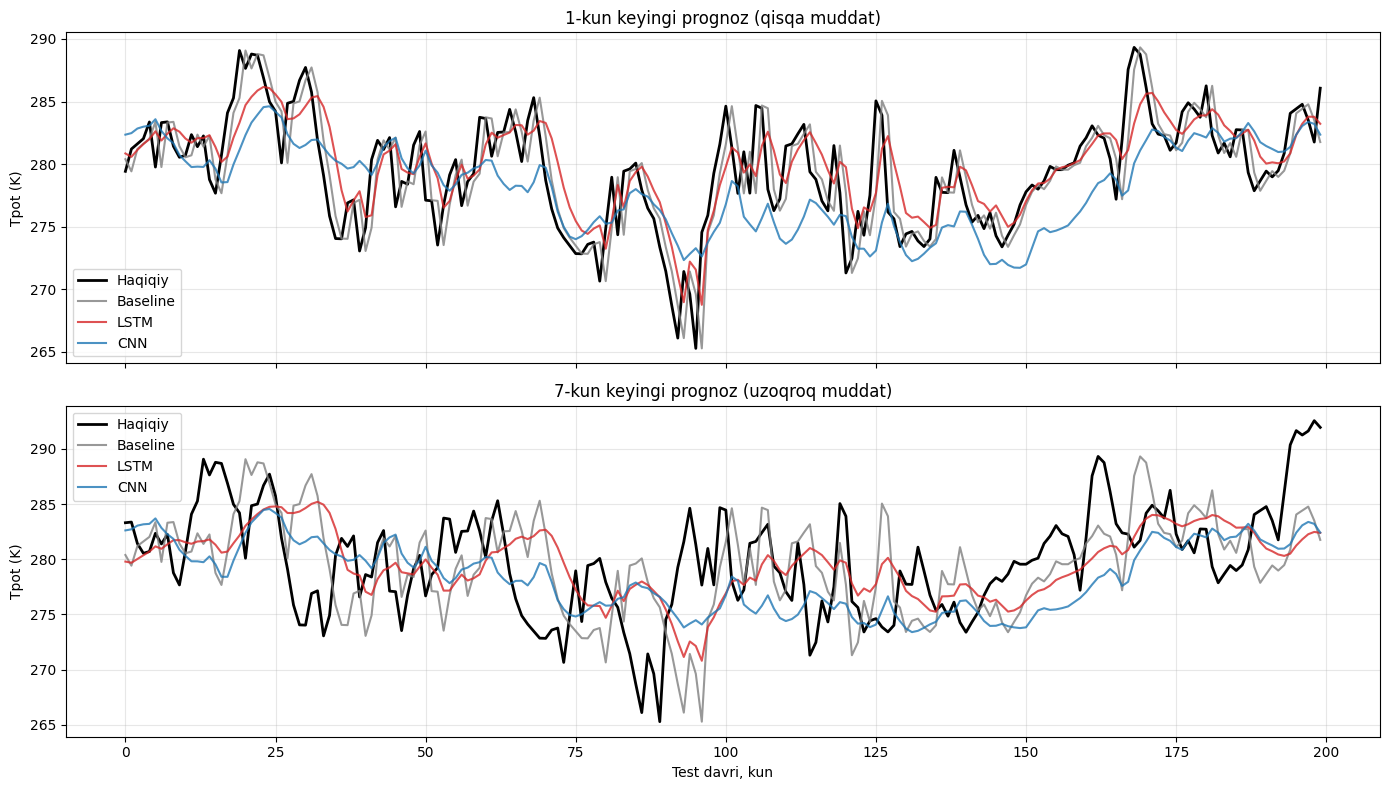

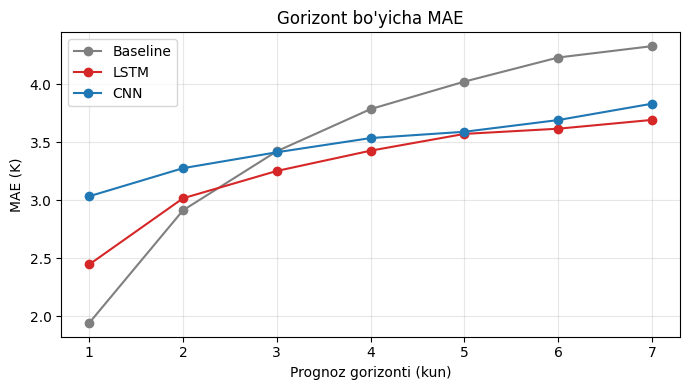

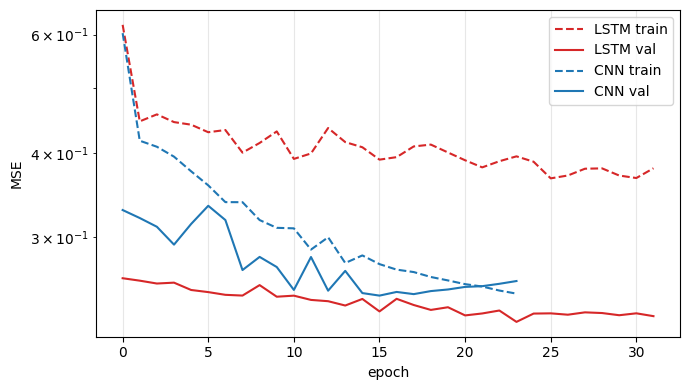

In [9]:
colors = {'Baseline':'tab:gray', 'LSTM':'tab:red', 'CNN':'tab:blue'}
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
N = min(200, len(y_te_true))
for a, step, title in [(ax[0], 0, '1-kun keyingi prognoz (qisqa muddat)'),
                       (ax[1], HORIZON-1, f'{HORIZON}-kun keyingi prognoz (uzoqroq muddat)')]:
    a.plot(y_te_true[:N, step], 'k', lw=2, label='Haqiqiy')
    for k, p in preds.items():
        a.plot(p[:N, step], color=colors[k], alpha=.8, label=k)
    a.set_title(title); a.set_ylabel('Tpot (K)'); a.grid(alpha=.3); a.legend()
ax[1].set_xlabel('Test davri, kun')
plt.tight_layout(); plt.savefig('task7_forecasts.png', dpi=150); plt.show()

# Gorizont bo'yicha xato: qaysi model qaysi kunda yaxshi?
plt.figure(figsize=(7,4))
for k, p in preds.items():
    plt.plot(range(1, HORIZON+1), np.mean(np.abs(y_te_true - p), axis=0), 'o-', color=colors[k], label=k)
plt.xlabel('Prognoz gorizonti (kun)'); plt.ylabel('MAE (K)'); plt.grid(alpha=.3); plt.legend()
plt.title('Gorizont bo\'yicha MAE'); plt.tight_layout()
plt.savefig('task7_mae_by_horizon.png', dpi=150); plt.show()

# O'qitish egri chiziqlari
plt.figure(figsize=(7,4))
for k, h in hists.items():
    plt.plot(h['loss'], color=colors[k], ls='--', label=f'{k} train')
    plt.plot(h['val_loss'], color=colors[k], label=f'{k} val')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('task7_loss.png', dpi=150); plt.show()